# Failure analysis (phone set)

Instance matching, failure tags and overlays for the 40 phone photos, from the exported predictions (`runs/<run_id>/predictions/phone.json`). No model is loaded, no GPU needed.

- A prediction is shown and matched when its score is at least `SCORE_THRESHOLD` (default in `configs/base.yaml`, `failure_analysis`). AP has no such threshold, so the counts here are not AP. The scores of different models are not calibrated to each other.
- Each GT instance has one tag. The exact rules are in the docstring of `iiss.analysis.failures`. The tags describe the masks, not the cause.
- `no_gt` = a prediction without a related GT. It is not always a false positive: the object may be real but not annotated.
- `SMOKE = True` uses one run per model and shows one photo.

## Parameters

In [1]:
SIZE = 640                 # input size of the gallery
SCORE_THRESHOLD = None     # None: value from configs/base.yaml
PER_TAG = 3                # candidates per failure tag
PHOTO = 'IMG_20261124_172303.jpg'   # photo for the detail section
OUT_DIR = 'results/failures'
SMOKE = False

In [2]:
%config InlineBackend.figure_formats = ['jpeg']
import matplotlib.pyplot as plt
import pandas as pd

from iiss.analysis import failures as fa
from iiss.analysis.domain_shift import run_ids
from iiss.analysis.failure_viz import compare_runs

pd.set_option('display.max_columns', 30, 'display.max_rows', 100, 'display.width', 200)
pd.set_option('display.max_colwidth', 90, 'display.float_format', '{:.2f}'.format)
gallery_runs = run_ids(sizes=[SIZE])
runs = gallery_runs if SMOKE else run_ids()
limits = fa.default_limits(score_threshold=SCORE_THRESHOLD)
issues = fa.settings()['label_issues']
print(limits, runs, sep='\n')

Limits(score_threshold=0.25, match_iou=0.5, good_iou=0.75, partial_iou=0.1)
['yolo_s320_seed42', 'yolo_s640_seed42', 'yolo_s960_seed42', 'maskrcnn_s320_seed42', 'maskrcnn_s640_seed42', 'maskrcnn_s960_seed42', 'm2f_s320_seed42', 'm2f_s640_seed42', 'm2f_s960_seed42']


## Match all runs

In [3]:
split = fa.load_gt_set('phone')
matches = fa.match_runs(runs, split, limits)
instances = fa.instance_table(matches, split)
print(len(instances), 'rows =', len(runs), 'runs x', len(split.annotations), 'GT instances')

1494 rows = 9 runs x 166 GT instances


## Tags per run

Number of GT instances per tag, then the shown predictions per kind.

In [4]:
display(fa.tag_counts(instances), fa.prediction_counts(matches))

tag,ok,mask_leak,mask_incomplete,split,merged,wrong_class,low_score,missed
run_id,,,,,,,,
yolo_s320_seed42,27,6,3,0,5,35,14,76
yolo_s640_seed42,27,6,4,0,5,25,24,75
yolo_s960_seed42,18,6,3,1,7,17,26,88
maskrcnn_s320_seed42,29,16,11,2,14,39,5,50
maskrcnn_s640_seed42,36,17,8,3,10,40,5,47
maskrcnn_s960_seed42,35,18,5,3,11,40,4,50
m2f_s320_seed42,41,17,5,0,7,39,12,45
m2f_s640_seed42,35,12,3,2,13,39,15,47
m2f_s960_seed42,37,18,4,1,11,42,14,39


,matched,duplicate,wrong_class,poor_mask,no_gt
run_id,,,,,
yolo_s320_seed42,34,3,45,3,76
yolo_s640_seed42,32,5,25,6,53
yolo_s960_seed42,26,1,21,7,36
maskrcnn_s320_seed42,46,4,68,25,128
maskrcnn_s640_seed42,53,2,81,24,163
maskrcnn_s960_seed42,48,5,62,37,162
m2f_s320_seed42,58,1,49,3,50
m2f_s640_seed42,46,0,44,8,55
m2f_s960_seed42,53,3,55,11,109


Share of each tag by condition (percent of the GT instances of the condition).

In [5]:
by_condition = fa.tag_counts(instances, ['condition', 'run_id'])
by_condition.div(by_condition.sum(axis=1), axis=0).mul(100).round(1)

tag                               ok  mask_leak  mask_incomplete  split  merged  wrong_class  low_score  missed
condition run_id                                                                                               
normal    yolo_s320_seed42     22.00       4.90             2.40   0.00    4.10        22.80       9.80   34.10
          yolo_s640_seed42     22.00       4.90             3.30   0.00    4.10        18.70      18.70   28.50
          yolo_s960_seed42     14.60       4.90             2.40   0.80    5.70        13.00      17.90   40.70
          maskrcnn_s320_seed42 23.60       4.90             7.30   1.60    6.50        30.10       2.40   23.60
          maskrcnn_s640_seed42 29.30       4.10             6.50   2.40    3.30        30.90       1.60   22.00
          maskrcnn_s960_seed42 26.80       5.70             4.10   2.40    5.70        30.90       3.30   21.10
          m2f_s320_seed42      28.50       8.10             4.10   0.00    2.40        30.10       7.30   19.50
          m2f_s640_seed42      27.60       2.40             2.40   1.60    5.70        28.50      12.20   19.50
          m2f_s960_seed42      30.10       6.50             3.30   0.80    4.10        32.50       9.80   13.00
low_light yolo_s320_seed42      0.00       0.00             0.00   0.00    0.00        16.30       4.70   79.10
          yolo_s640_seed42      0.00       0.00             0.00   0.00    0.00         4.70       2.30   93.00
          yolo_s960_seed42      0.00       0.00             0.00   0.00    0.00         2.30       9.30   88.40
          maskrcnn_s320_seed42  0.00      23.30             4.70   0.00   14.00         4.70       4.70   48.80
          maskrcnn_s640_seed42  0.00      27.90             0.00   0.00   14.00         4.70       7.00   46.50
          maskrcnn_s960_seed42  4.70      25.60             0.00   0.00    9.30         4.70       0.00   55.80
          m2f_s320_seed42      14.00      16.30             0.00   0.00    9.30         4.70       7.00   48.80
          m2f_s640_seed42       2.30      20.90             0.00   0.00   14.00         9.30       0.00   53.50
          m2f_s960_seed42       0.00      23.30             0.00   0.00   14.00         4.70       4.70   53.50

Which classes are predicted instead (all runs).

In [6]:
wrong = instances[instances['tag'] == 'wrong_class']
wrong.groupby(['name', 'predicted_as']).size().sort_values(ascending=False).head(15)

name               predicted_as      
ceiling-merged     wall-other-merged     33
table-merged       floor-wood            29
pillow             wallet                21
book               wallet                21
backpack           person                19
wall-other-merged  floor-other-merged    19
bowl               pan                   15
chair              stairs                13
towel              person                 9
bed                floor-other-merged     9
towel              blanket                7
chair              wall-other-merged      6
backpack           stairs                 6
plate              box                    5
wall-other-merged  table-merged           5
dtype: int64

## Photos

Matched GT instances per run. Photos with the lowest share come first.

In [7]:
fa.photo_table(instances, issues)

,condition,scene,n_gt,yolo_s320_seed42,yolo_s640_seed42,yolo_s960_seed42,maskrcnn_s320_seed42,maskrcnn_s640_seed42,maskrcnn_s960_seed42,m2f_s320_seed42,m2f_s640_seed42,m2f_s960_seed42,matched_share,label_issue
file_name,,,,,,,,,,,,,,
IMG_20261124_172429.jpg,normal,ceiling_light,4,0,0,0,0,0,0,0,0,0,0.00,
IMG_20261124_172737.jpg,low_light,table_bottle_plate,4,0,0,0,0,0,0,0,0,0,0.00,
IMG_20261124_172743.jpg,low_light,chair,3,0,0,0,0,0,0,0,0,0,0.00,
IMG_20261124_172810.jpg,low_light,table_bottle_plate,3,0,0,0,0,0,0,0,0,0,0.00,
IMG_20261124_172813.jpg,low_light,table_bottle_plate,3,0,0,0,0,0,0,0,0,0,0.00,
IMG_20261124_172827.jpg,low_light,bed_corner,5,0,0,0,0,0,0,0,0,0,0.00,
IMG_20261124_172426.jpg,normal,ceiling_light,3,0,0,0,0,0,0,0,1,0,0.04,
IMG_20261124_172430.jpg,normal,ceiling_light,4,0,0,0,0,0,0,1,0,1,0.06,
IMG_20261124_172832.jpg,low_light,chair,3,0,0,0,0,0,0,2,0,0,0.07,


## Candidates

For every failure tag: failures shared by several models first, then larger objects, each scene once per tag. Photos with a known label issue are left out.

In [8]:
at_size = instances[instances['input_size'] == SIZE]
candidates = fa.candidates(at_size, PER_TAG, exclude=issues)
if not SMOKE:
    fa.write_failure_tables(instances, candidates, OUT_DIR)
candidates

,tag,file_name,scene,condition,gt_id,name,area_fraction,n_runs,runs
0,mask_leak,IMG_20261124_172438.jpg,bed_corner,normal,93,wall-other-merged,0.46,3,"yolo_s640_seed42, maskrcnn_s640_seed42, m2f_s640_seed42"
1,mask_leak,IMG_20261124_172753.jpg,towel_door,low_light,137,wall-other-merged,0.61,2,"maskrcnn_s640_seed42, m2f_s640_seed42"
2,mask_leak,IMG_20261124_172813.jpg,table_bottle_plate,low_light,151,wall-other-merged,0.27,2,"maskrcnn_s640_seed42, m2f_s640_seed42"
3,mask_incomplete,IMG_20261124_172306.jpg,backpack_chair,normal,49,floor-other-merged,0.20,2,"maskrcnn_s640_seed42, m2f_s640_seed42"
4,mask_incomplete,IMG_20261124_172112.jpg,book_table,normal,21,book,0.40,1,maskrcnn_s640_seed42
5,mask_incomplete,IMG_20261124_171922.jpg,bed_pillow,normal,8,bed,0.35,1,yolo_s640_seed42
6,split,IMG_20261124_172624.jpg,backpack_chair,normal,111,floor-other-merged,0.22,2,"maskrcnn_s640_seed42, m2f_s640_seed42"
7,split,IMG_20261124_172501.jpg,chair,normal,103,floor-other-merged,0.42,1,maskrcnn_s640_seed42
8,merged,IMG_20261124_172438.jpg,bed_corner,normal,94,wall-other-merged,0.39,3,"yolo_s640_seed42, maskrcnn_s640_seed42, m2f_s640_seed42"
9,merged,IMG_20261124_172430.jpg,ceiling_light,normal,90,wall-other-merged,0.13,3,"yolo_s640_seed42, maskrcnn_s640_seed42, m2f_s640_seed42"


## Gallery

Fill color = class (same class, same color within a row). White outline = GT or matched prediction, black outline = prediction without a match.

IMG_20261124_172438.jpg | mask_leak: wall-other-merged; merged: wall-other-merged


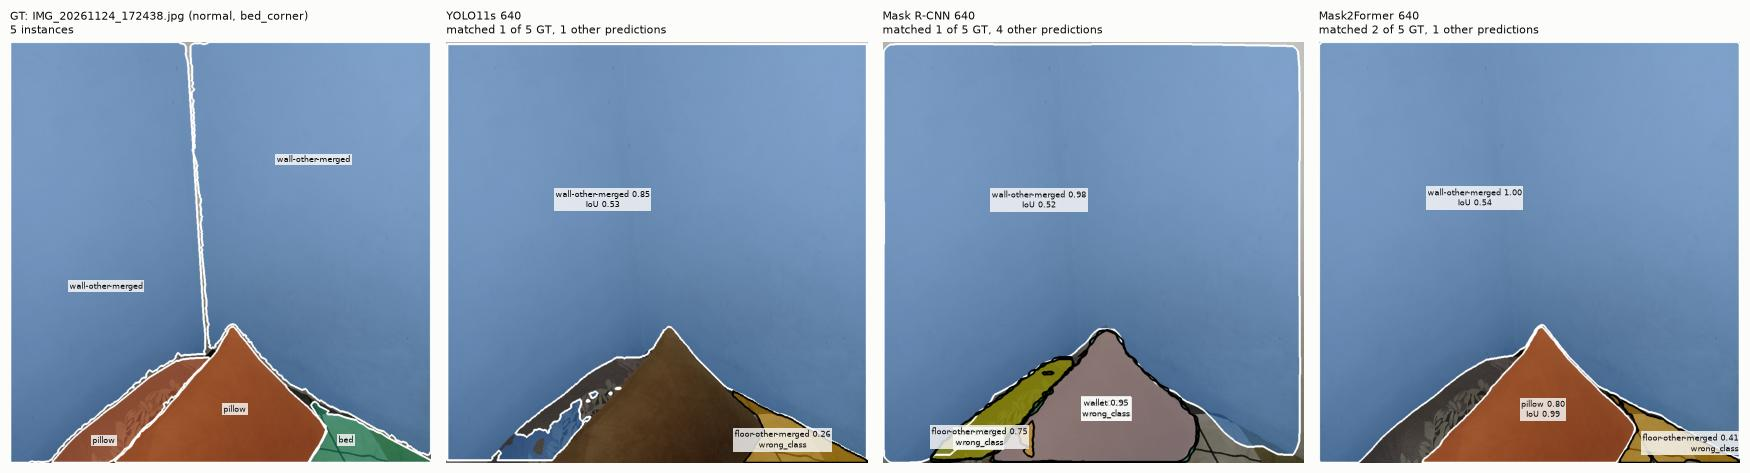

IMG_20261124_172753.jpg | mask_leak: wall-other-merged


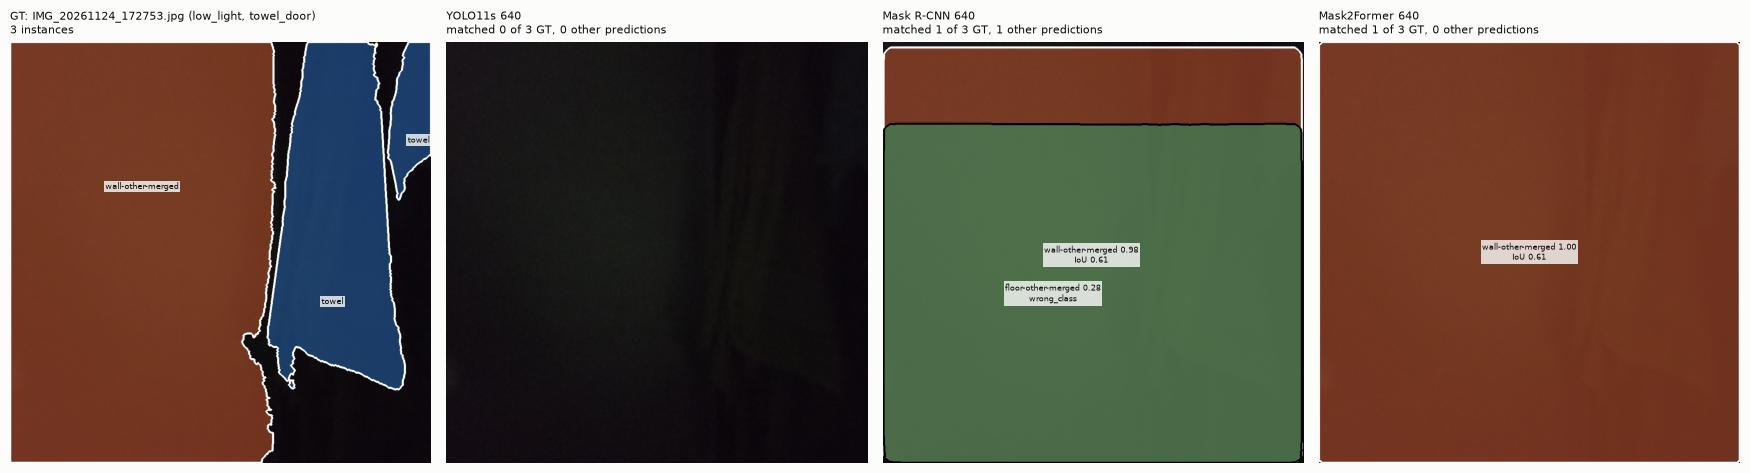

IMG_20261124_172813.jpg | mask_leak: wall-other-merged


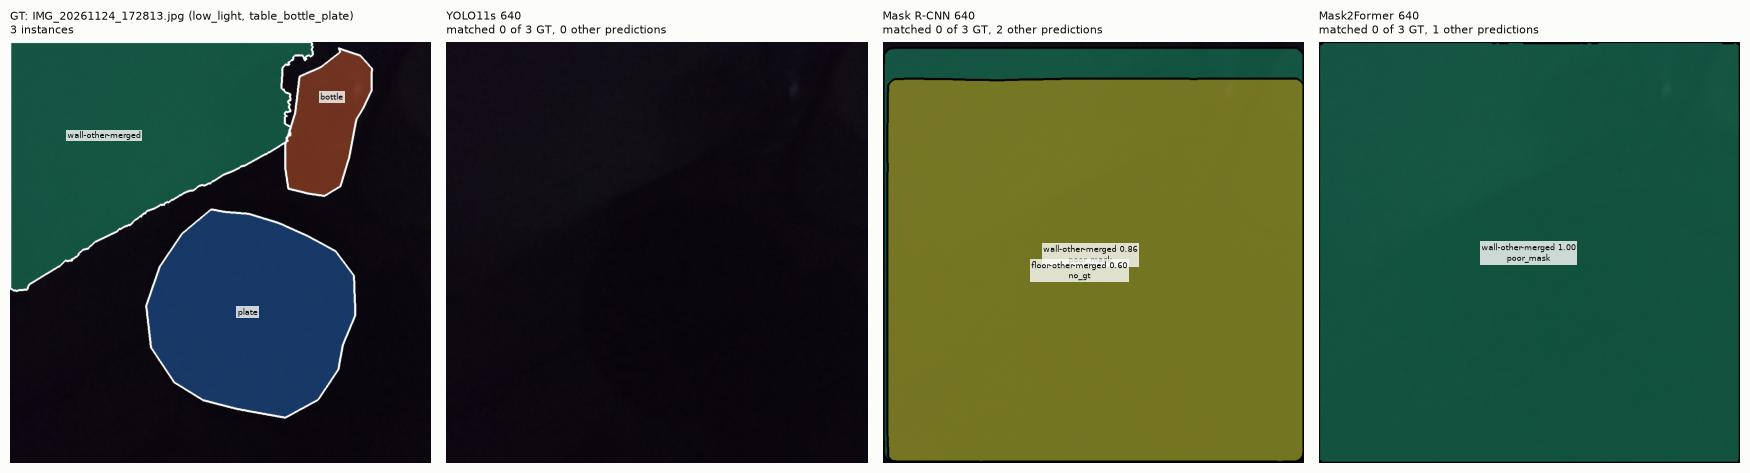

IMG_20261124_172306.jpg | mask_incomplete: floor-other-merged; missed: chair


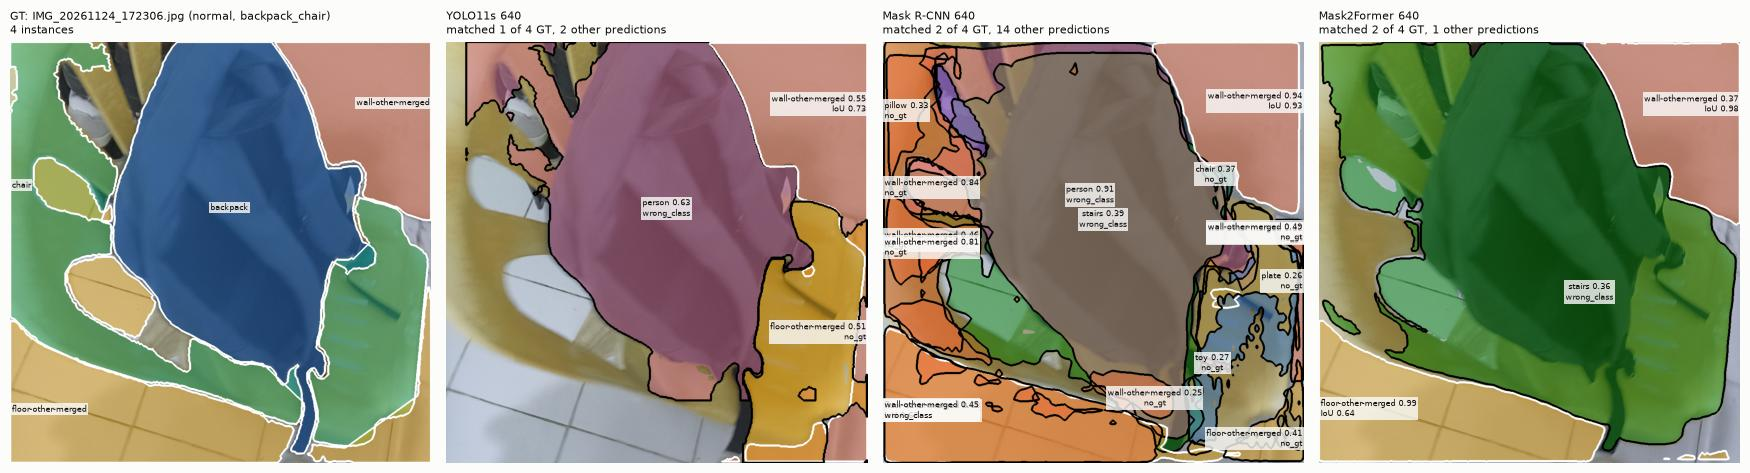

IMG_20261124_172112.jpg | mask_incomplete: book; merged: table-merged


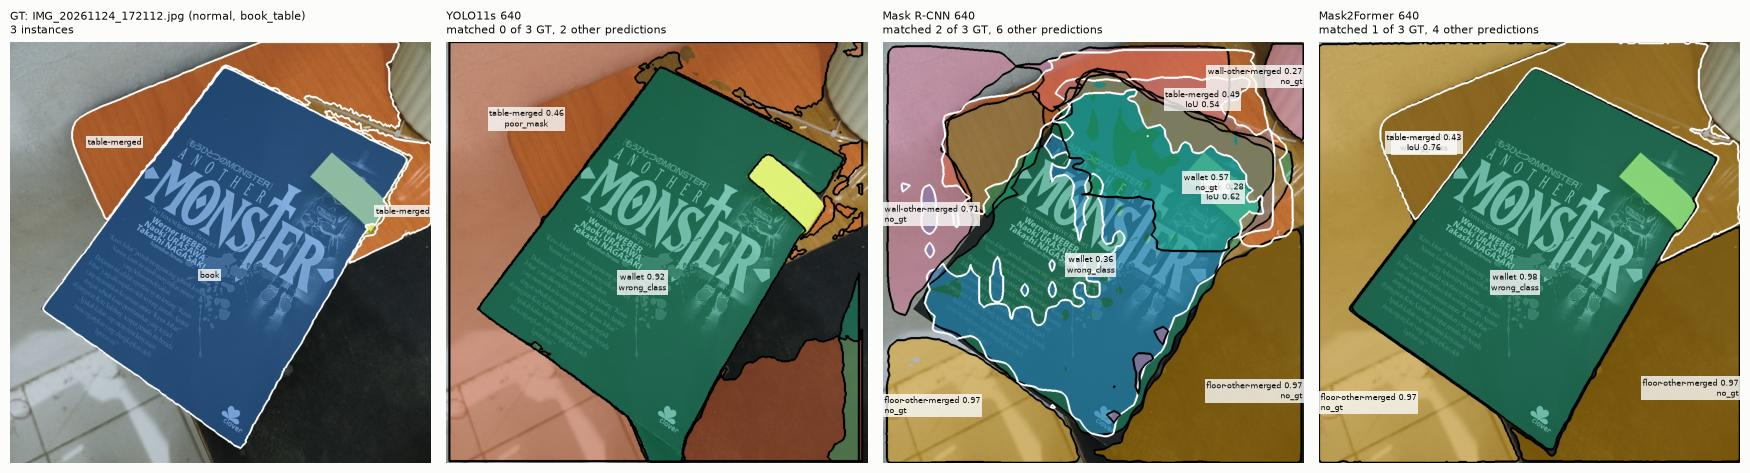

IMG_20261124_171922.jpg | mask_incomplete: bed


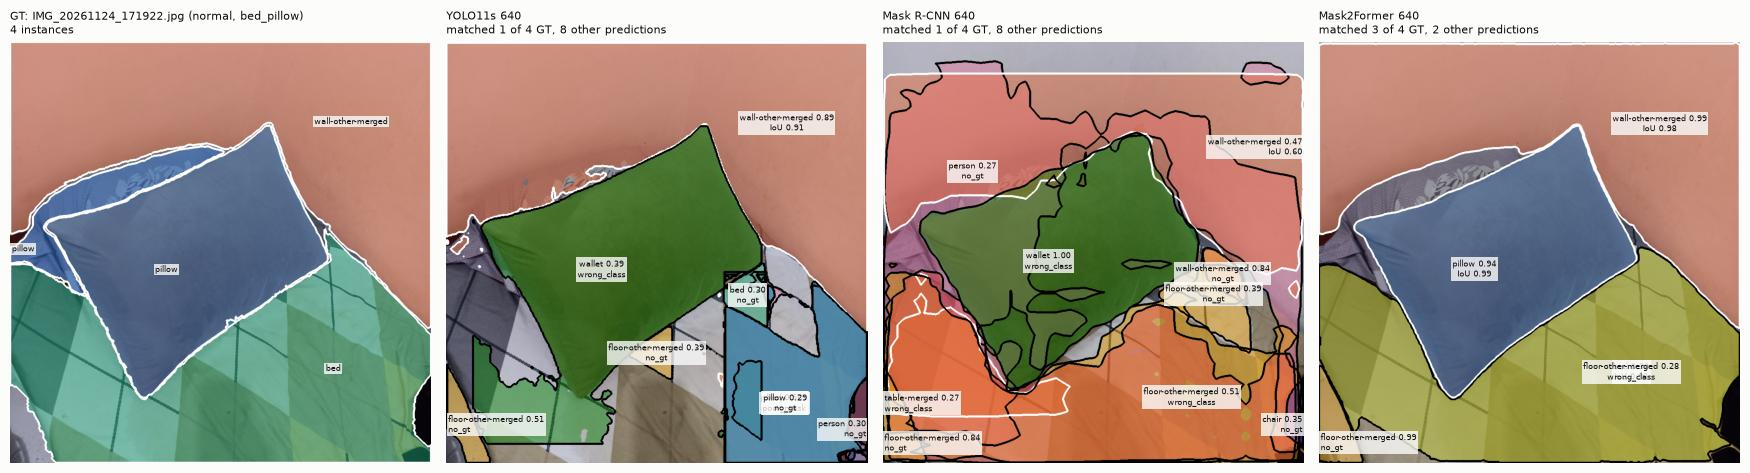

IMG_20261124_172624.jpg | split: floor-other-merged


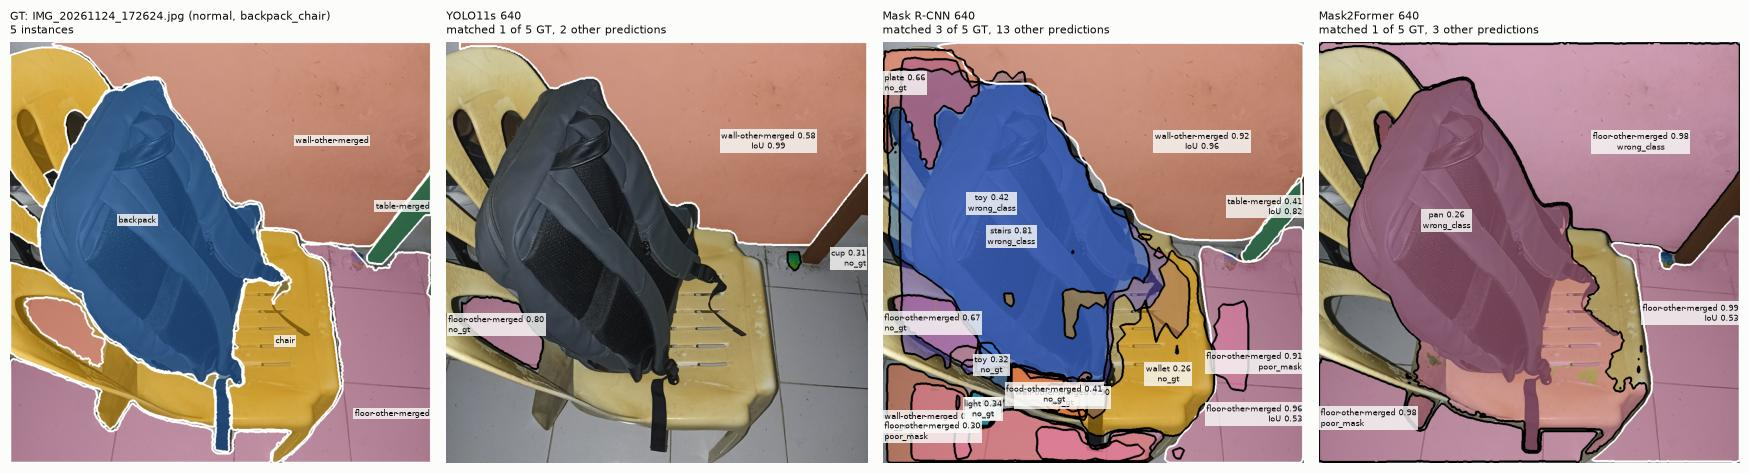

IMG_20261124_172501.jpg | split: floor-other-merged; low_score: table-merged


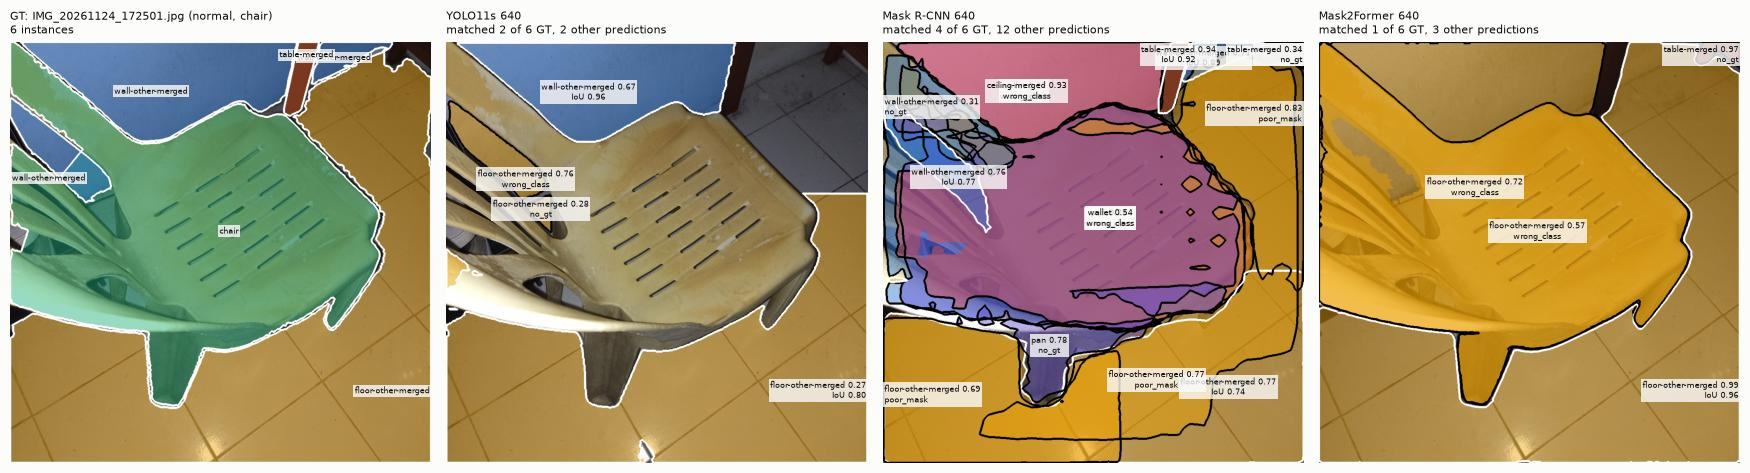

IMG_20261124_172430.jpg | merged: wall-other-merged


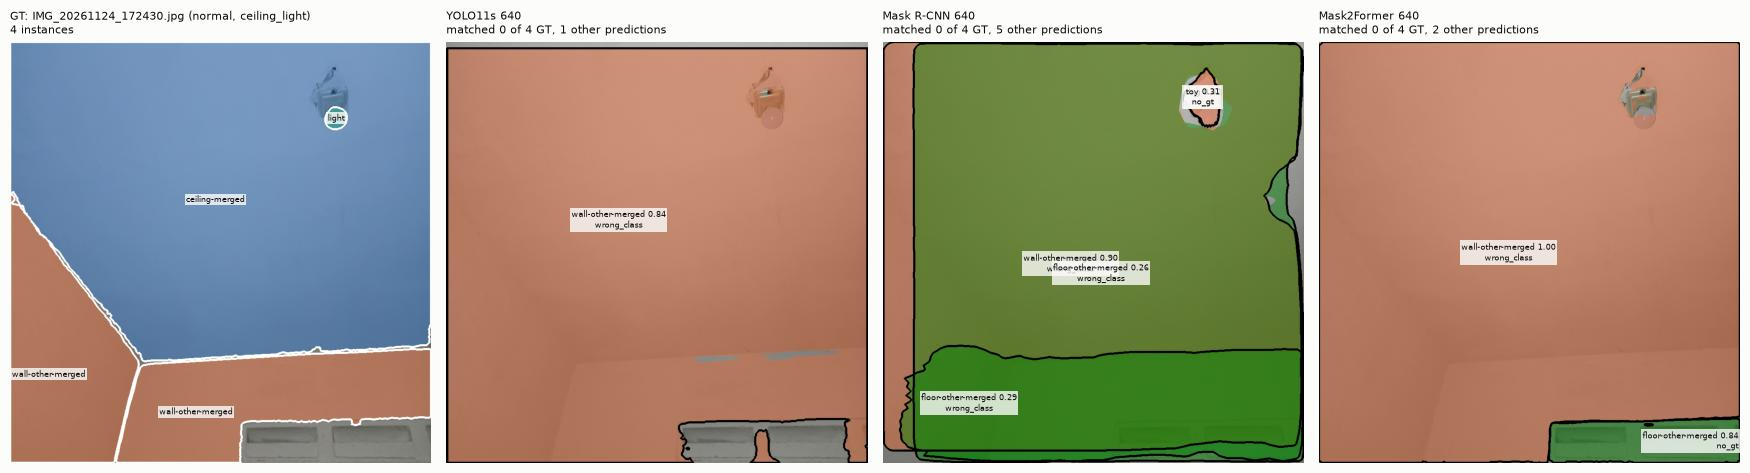

IMG_20261124_172426.jpg | wrong_class: ceiling-merged


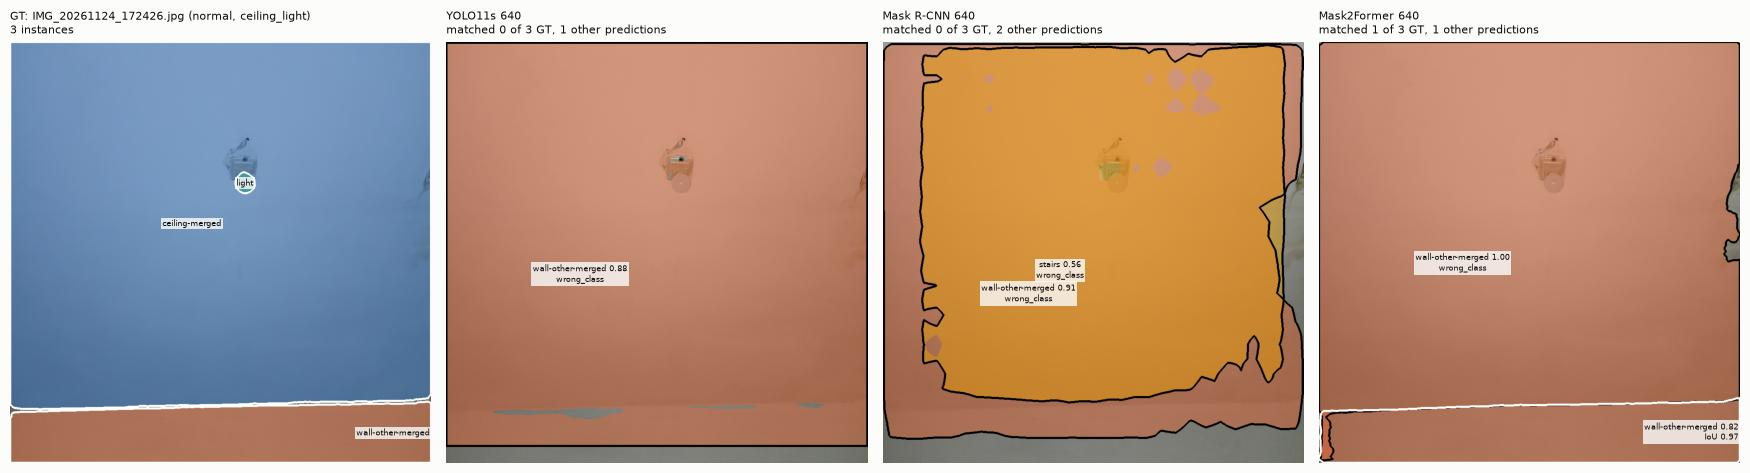

IMG_20261124_172303.jpg | wrong_class: backpack


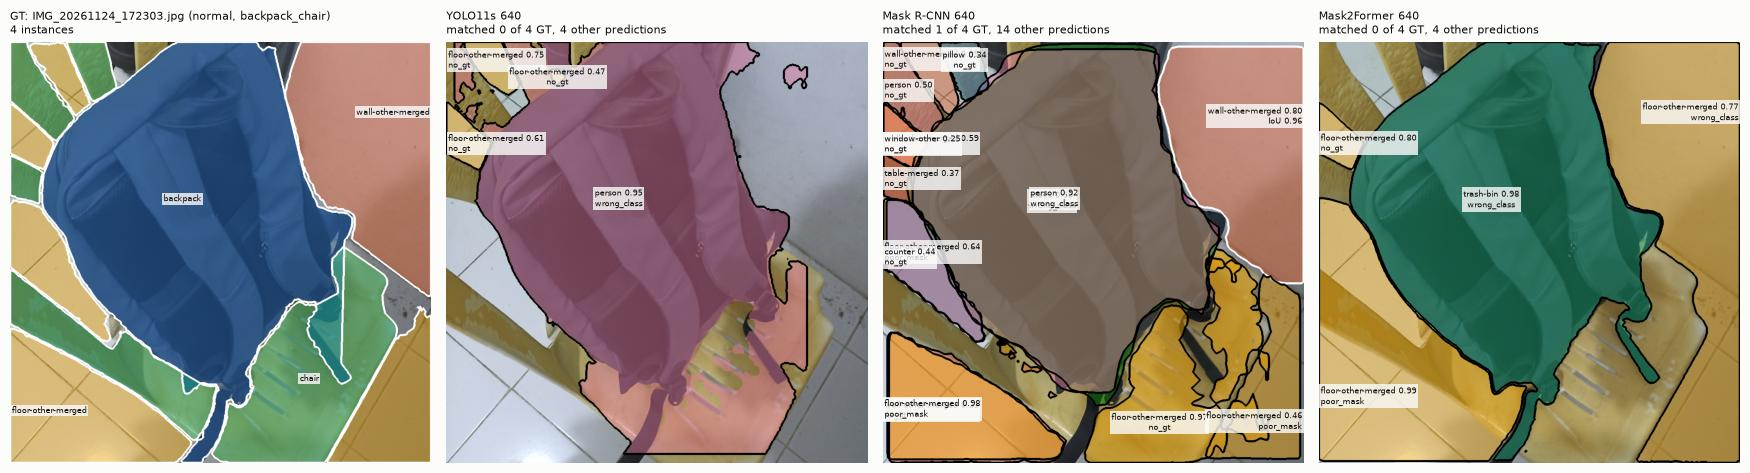

IMG_20261124_172119.jpg | wrong_class: book


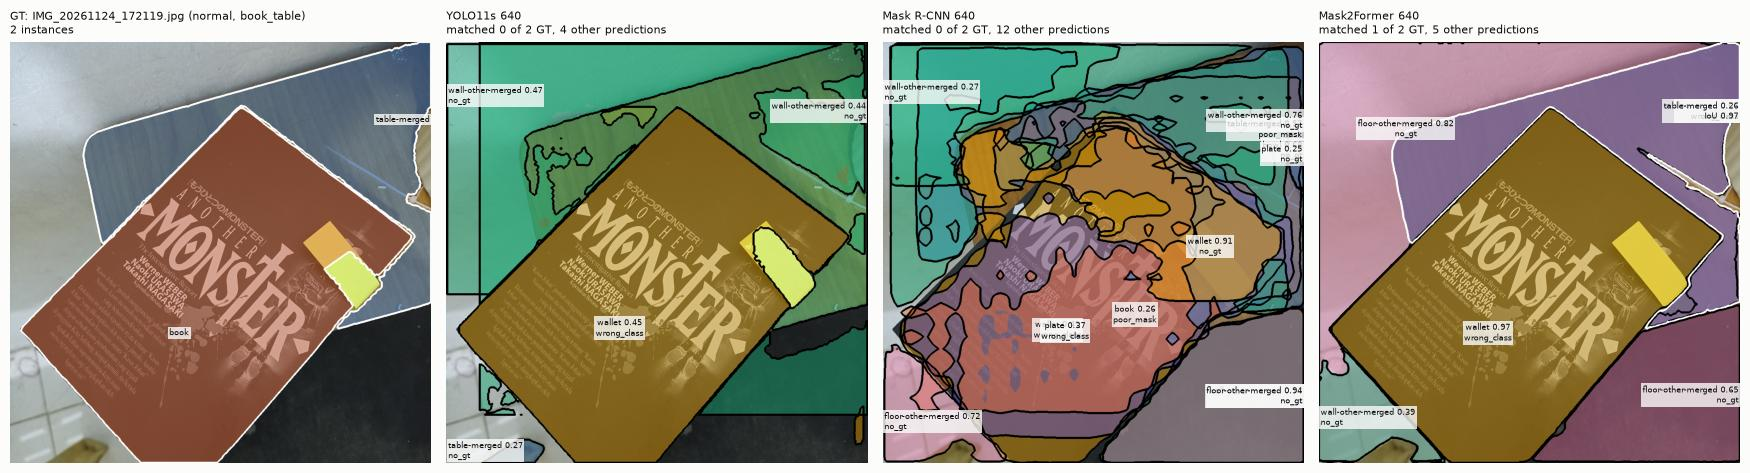

IMG_20261124_172233.jpg | low_score: plate


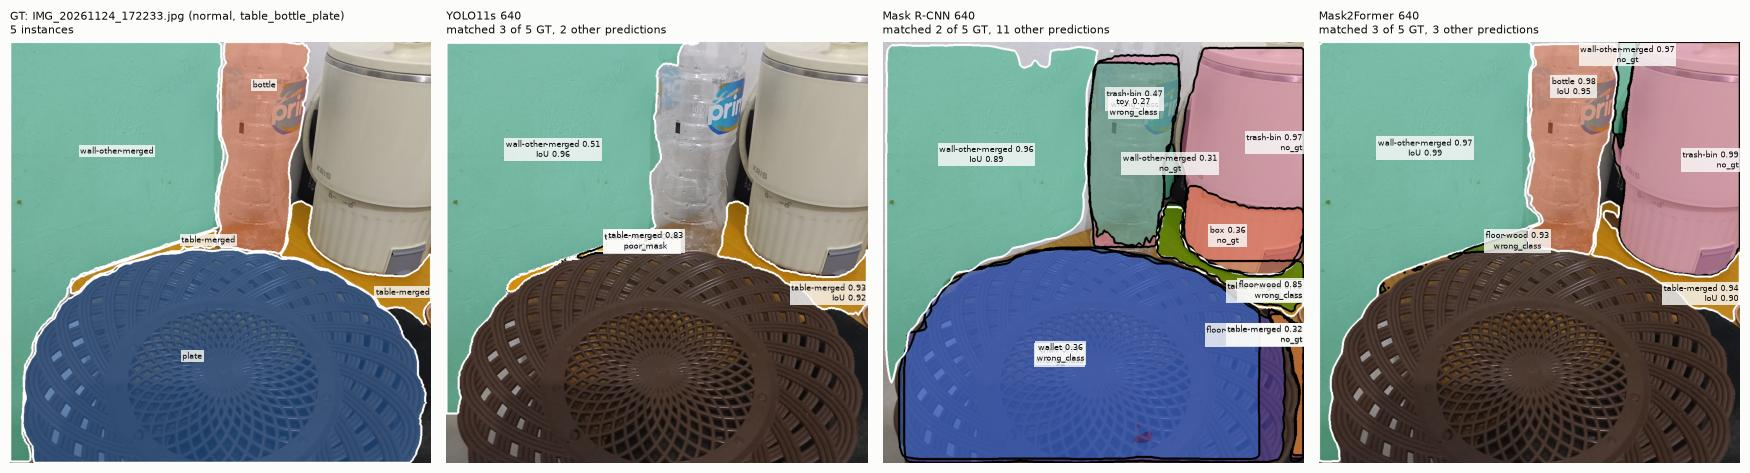

IMG_20261124_172401.jpg | low_score: wall-other-merged


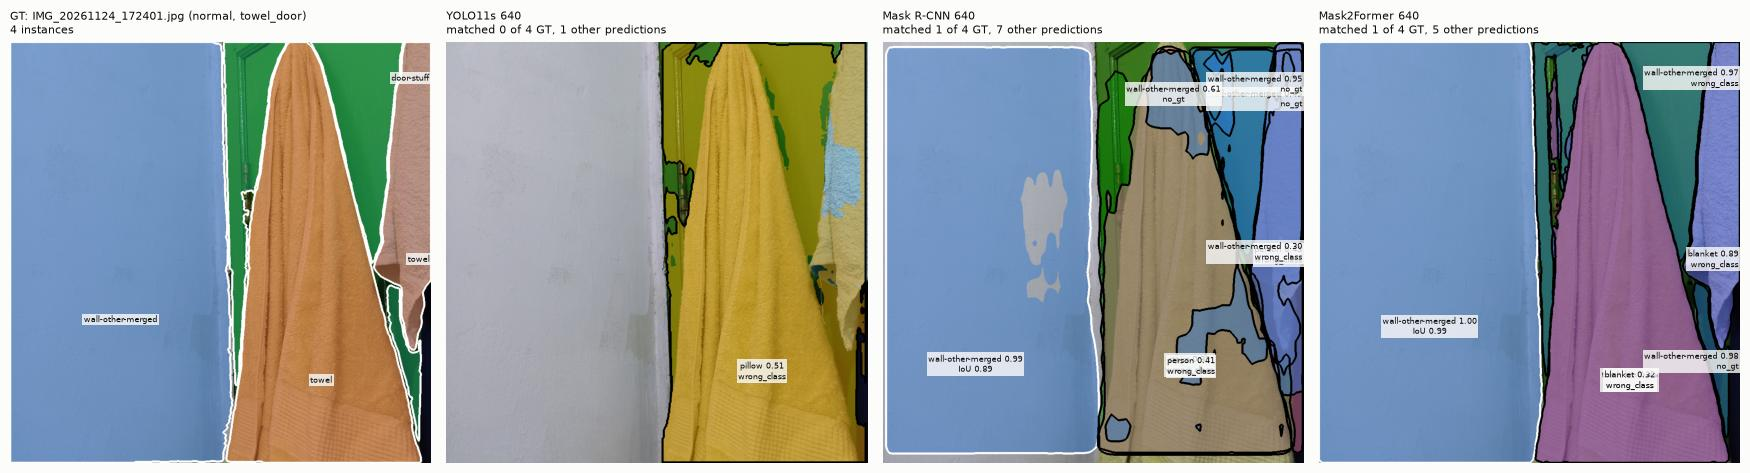

IMG_20261124_171925.jpg | missed: bed


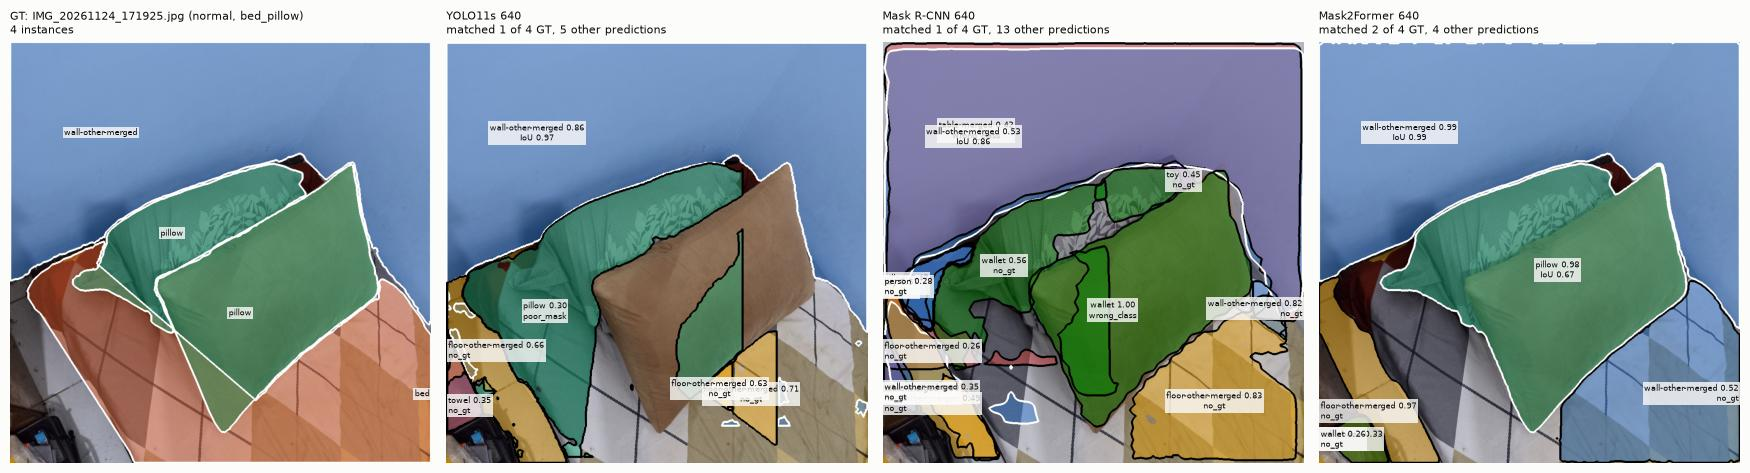

IMG_20261124_172737.jpg | missed: plate


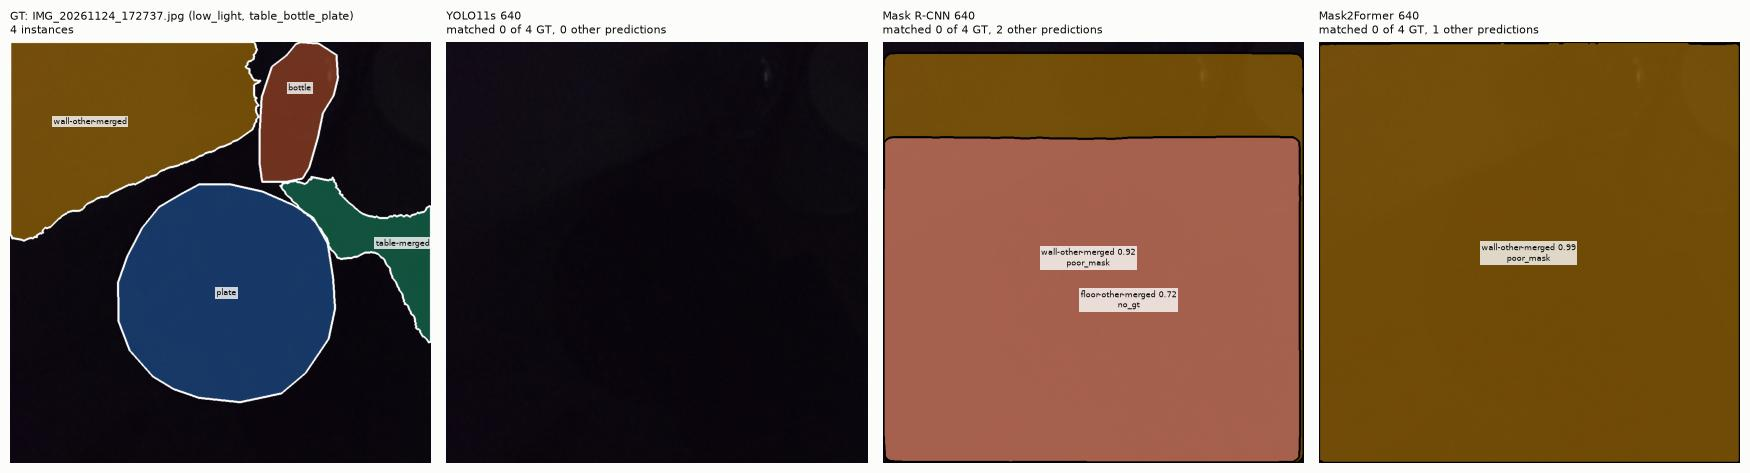

In [9]:
photos = list(dict.fromkeys(candidates['file_name']))
for name in photos[:1] if SMOKE else photos:
    tags = candidates.loc[candidates['file_name'] == name, ['tag', 'name']]
    print(name, '|', '; '.join(f'{t}: {n}' for t, n in tags.to_numpy()))
    compare_runs(split, name, matches, gallery_runs)
    plt.show()

## One photo in detail

Set `PHOTO` to any photo. The table shows the tag of every GT instance for every run, the figures show each model at the three input sizes.

In [10]:
fa.photo_detail(instances, PHOTO)

,run_id,yolo_s320_seed42,yolo_s640_seed42,yolo_s960_seed42,maskrcnn_s320_seed42,maskrcnn_s640_seed42,maskrcnn_s960_seed42,m2f_s320_seed42,m2f_s640_seed42,m2f_s960_seed42
gt_id,name,,,,,,,,,
38,backpack,wrong_class (person 0.66),wrong_class (person 0.95),missed,wrong_class (person 0.93),wrong_class (person 0.92),wrong_class (person 0.94),wrong_class (person 0.76),wrong_class (trash-bin 0.98),wrong_class (pan 0.36)
39,wall-other-merged,low_score (0.04),low_score (0.15),low_score (0.00),mask_leak (IoU 0.72),ok (IoU 0.96),ok (IoU 0.87),wrong_class (floor-other-merged 0.96),wrong_class (floor-other-merged 0.77),mask_leak (IoU 0.69)
40,chair,missed,missed,missed,missed,missed,missed,wrong_class (floor-other-merged 0.69),missed,missed
41,floor-other-merged,mask_incomplete (IoU 0.44),low_score (0.07),mask_incomplete (IoU 0.43),split (IoU 0.41),split (IoU 0.41),split (IoU 0.42),mask_incomplete (IoU 0.59),mask_incomplete (IoU 0.47),mask_incomplete (IoU 0.45)


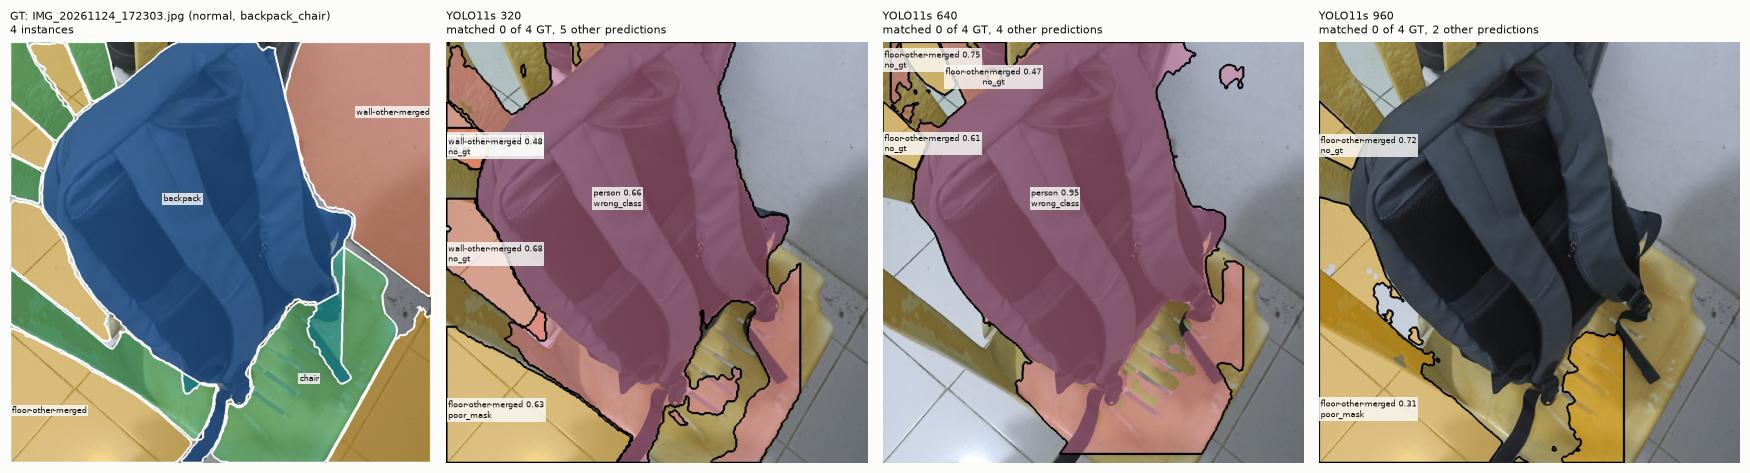

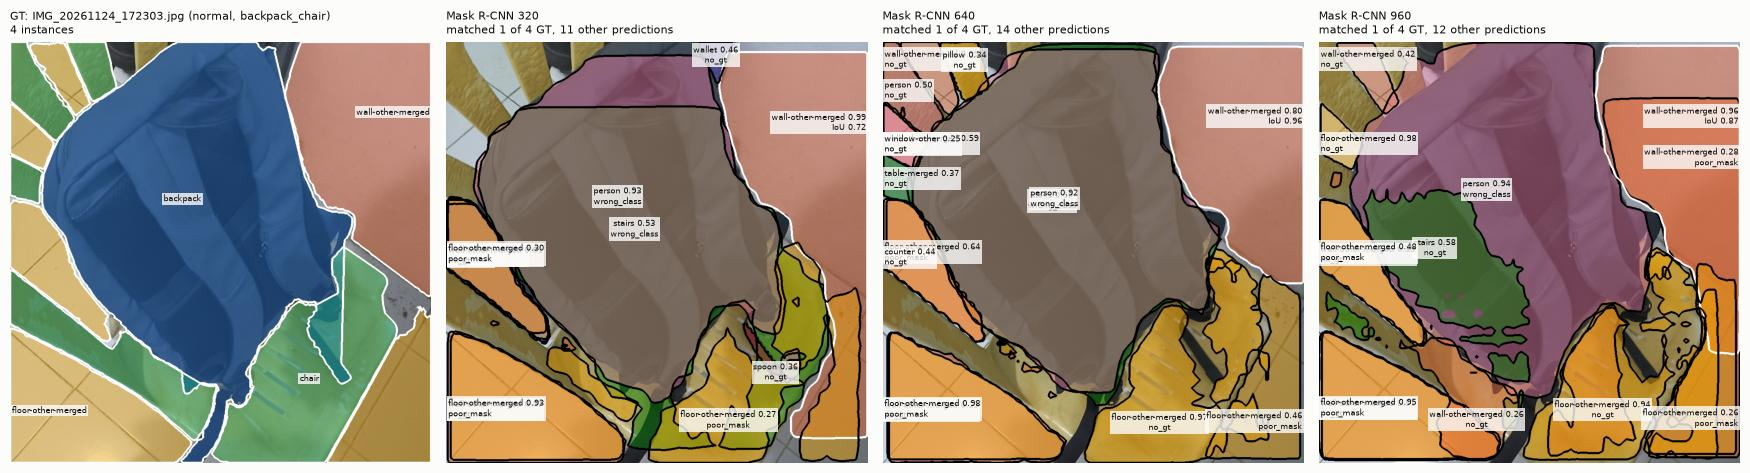

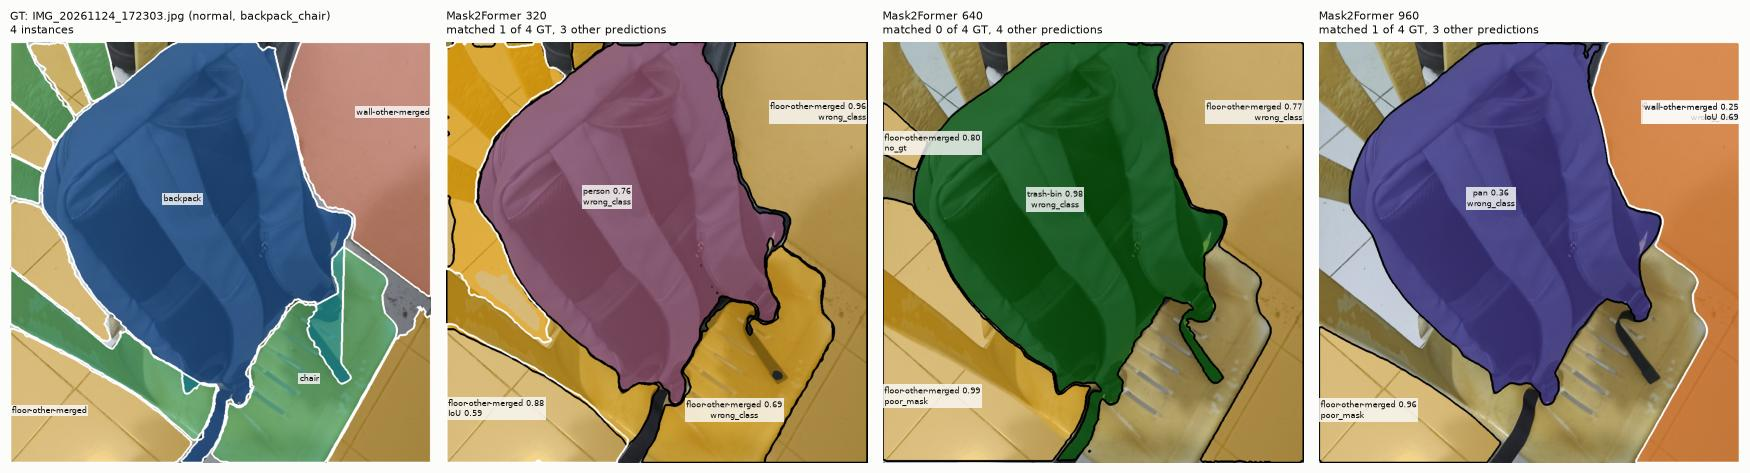

In [11]:
for model in ('yolo', 'maskrcnn', 'm2f'):
    compare_runs(split, PHOTO, matches, [r for r in runs if r.startswith(model + '_')])
    plt.show()

## Next step

Pick 5 photos with clear failures and write one hypothesis per photo: which instance and model fail, the failure type, and the mechanism of the model that explains it. Each hypothesis is then tested with one small inference-only experiment.